<a href="https://colab.research.google.com/github/Lillie-Walden/Lab-4/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [4]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/airbnb_listings.csv')

# Preview the dataset
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 459 entries, 0 to 458
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            459 non-null    int64  
 1   listing_url                                   459 non-null    object 
 2   scrape_id                                     459 non-null    int64  
 3   last_scraped                                  459 non-null    object 
 4   source                                        459 non-null    object 
 5   name                                          459 non-null    object 
 6   description                                   449 non-null    object 
 7   neighborhood_overview                         196 non-null    object 
 8   host_url                                      459 non-null    object 
 9   host_name                                     459 non-null    obj

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset contains business information about Airbnb properties including host attributes (name, location, response times/rates, etc.) There is also information about the listings themselves and the Airbnb as well.


2. There are 459 rows and 77 columns in this dataset.


## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [5]:
# Define the list of columns to drop if they exist in the dataframe
columns_to_drop = ['post_id', 'title', 'descr', 'details', 'address']

# Drop only the columns that actually exist in the DataFrame
existing_cols_to_drop = [col for col in columns_to_drop if col in df.columns]
df.drop(columns=existing_cols_to_drop, inplace=True)

# Display the remaining columns to verify
print(f"Dropped columns: {existing_cols_to_drop}")
print(f"New dataset shape: {df.shape}")

Dropped columns: []
New dataset shape: (459, 77)


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I did not drop any columns because there were none in my dataset that existed and seemed to be causing issues.

2. If I had columns like those and kept them in my model, we might have had information with data type down the line. There also could have been confusion with IDs if any of those numbers remained in the dataset.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Top 10 variables positively correlated with Price:
price                      1.000000
accommodates               0.579588
beds                       0.547032
bedrooms                   0.499286
bathrooms                  0.468030
estimated_revenue_l365d    0.249488
maximum_maximum_nights     0.122872
minimum_maximum_nights     0.112166
maximum_nights_avg_ntm     0.111271
availability_30            0.108409
Name: price, dtype: float64

Top 10 variables negatively correlated with Price:
minimum_nights_avg_ntm                        -0.065831
minimum_minimum_nights                        -0.066554
minimum_nights                                -0.075122
reviews_per_month                             -0.090843
review_scores_checkin                         -0.103223
longitude                                     -0.118913
review_scores_communication                   -0.131798
scrape_id                                           NaN
license                                             NaN
calcu

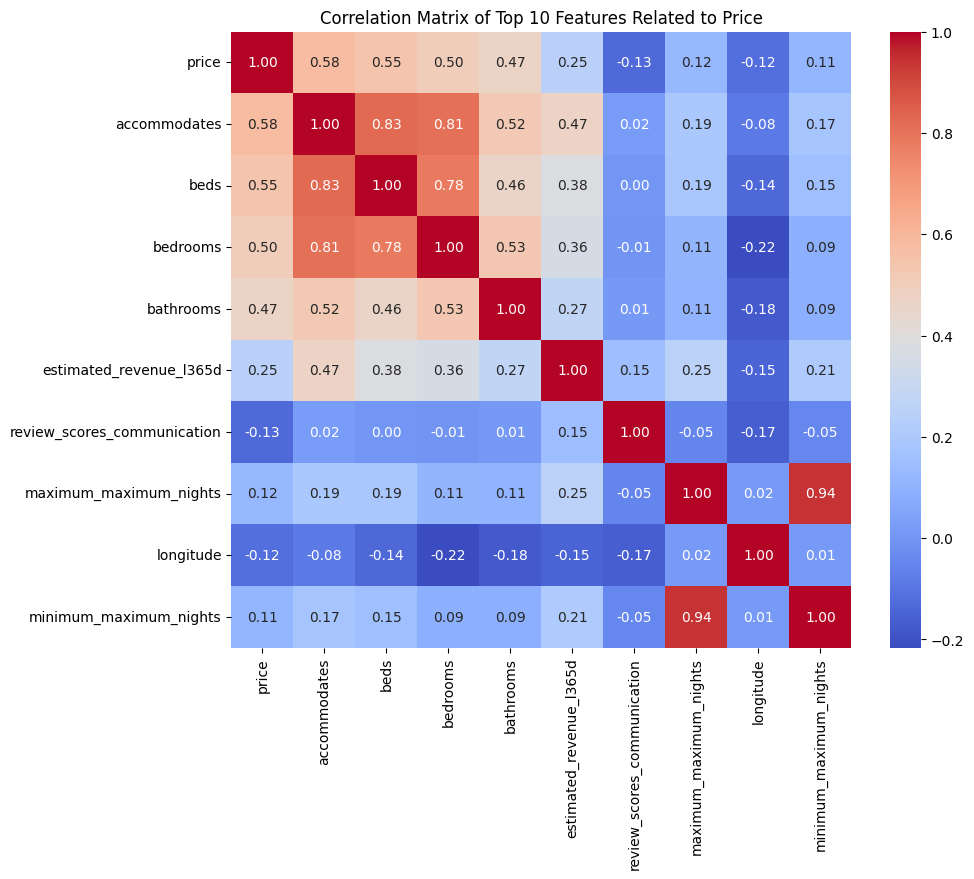

In [6]:
# 1. Select only the numeric columns from the DataFrame
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# 2. Generate the correlation matrix
corr_matrix = numeric_df.corr()

# 3. Extract correlations of all features with 'price' and sort them
price_correlations = corr_matrix['price'].sort_values(ascending=False)

print("Top 10 variables positively correlated with Price:")
print(price_correlations.head(10))
print("\nTop 10 variables negatively correlated with Price:")
print(price_correlations.tail(10))

# 4. Plot a heatmap of the top correlated variables with price for better visualization
top_corr_features = price_correlations.abs().sort_values(ascending=False).head(10).index
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix.loc[top_corr_features, top_corr_features], annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Top 10 Features Related to Price')
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?

- Strongest Positive Correlation with Price: Accomodates (0.58), beds (0.55), bedrooms (0.50), bathrooms (0.47).

Strongest Negative Correlation with Price: Review Scores Communication (-0.13), longitude (-0.12), and review scores checkin (-0.10).


2. Which variables might be useful predictors?

I think that any size/capacity metrics might be useful predictors in price because they tend to have a strong positive, linear relationship with price. They typically add value to the property and raise the price. If there are poor review scores for communication this is also going to influence the price, alongside the experiences that individuals had while staying at thes Airbnbs.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [7]:
# Define target variable (y)
y = df['price']

# Define predictors (X) - we select numeric columns, then drop target and non-predictive ID columns
# Also drop columns containing mostly missing values (like 'license' or 'scrape_id' which had NaN correlations)
predictors_df = df.select_dtypes(include=['int64', 'float64']).copy()

cols_to_remove = ['price', 'id', 'scrape_id', 'license']
existing_cols_to_remove = [col for col in cols_to_remove if col in predictors_df.columns]

X = predictors_df.drop(columns=existing_cols_to_remove)

# Fill any remaining NaNs in numeric predictors with their median to avoid training errors
X = X.fillna(X.median())

print(f"Target (y) shape: {y.shape}")
print(f"Features (X) shape: {X.shape}")

Target (y) shape: (459,)
Features (X) shape: (459, 40)


### Reflection:
1. What features are you using?

I am using 40 numeric features from the dataset, which includes many structural attributes of the Airbnbs. Anything that people are directly looking at: accomodates, beds, bedrooms, bathrooms, review scores, booking rates, etc.


2. Why is this a regression problem and not a classification problem?
  
This is a regression problem because the target variable we are predicting is price, which is continuous and numerical. If we were predicting discrete categories, then it would be a classification problem.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [8]:
# Split the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Print the shapes of the split datasets to confirm
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (367, 40)
X_test shape: (92, 40)
y_train shape: (367,)
y_test shape: (92,)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [9]:
# 1. Initialize the Linear Regression Model
model = LinearRegression()

# 2. Fit the model to our training data
model.fit(X_train, y_train)

# 3. Predict the listing prices on the test data
y_pred = model.predict(X_test)

print("Model training complete! Predictions have been generated for the test set.")

Model training complete! Predictions have been generated for the test set.


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [10]:
# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)

# Calculate R-squared (R2) Score
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Squared Error (MSE): 8752.53
R-squared (R2) Score: -0.5595


### Reflection:
1. What is your R² score? How well does your model explain price variation?

My R-Squared Score is -0.5595. This score shows that our baseline model performs worse than the average price of the dataset. This does not explain price variation very well at all because there are too many features included that are not necessary (40 features). This created overfitting and too much noise on the testing dataset.

2. Is your MSE large or small? What could you do to improve it?

MSE Score: 8572.53.
This is a very large value. To improve this number, we could remove noisy, irrelevent, or multicollinearity variable issues. If we use feature selection to keep only the 3-5 strongest features, then we can handle some massive outliers in the price variable. This will all help to improve the MSE number.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [11]:
# Create a DataFrame of feature names and their regression coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_,
    'Absolute_Impact': abs(model.coef_)
})

# Sort the table so that the most impactful features (by absolute value) are at the top
coef_df = coef_df.sort_values(by='Absolute_Impact', ascending=False).reset_index(drop=True)

# Display the top 20 most impactful features
coef_df.head(20)

,Feature,Coefficient,Absolute_Impact
0,latitude,-784.618582,784.618582
1,longitude,-326.230449,326.230449
2,review_scores_communication,-137.706179,137.706179
3,review_scores_value,135.102802,135.102802
4,review_scores_checkin,-91.976509,91.976509
5,minimum_nights_avg_ntm,36.504410,36.504410
6,maximum_minimum_nights,-36.232262,36.232262
7,bathrooms,32.631440,32.631440
8,review_scores_cleanliness,-30.029879,30.029879
9,review_scores_accuracy,20.872583,20.872583


### Reflection:
1. Which features increased price the most?

Looking at the coefficient table, Review Schores Value, Minimum Nights Average, and any of the physical aspects of Airbnbs (bathrooms, beds, accomodates) increased the price the most.


2. Were any surprisingly negative?

Yes, review scores communication and review scores cleanliness showed negative coefficients, which is slightly surprising because normally higher quality ratings would align with higher prices. I also need to not include the geographic coordinates probably because they could skew the data greatly.


3. What business insight could you draw from this?

I can see that including geographic coordinates directly in linear regression can severely skew coefficients. This could create multicollinearity issues  and accidentally dominate the model. I also see that the physical capabilities of Airbnb listings still remain very predictable in price correlation.

## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [14]:
# 1. Choose top 4 features without geographic coordinates (excluding latitude/longitude)
# Based on our baseline analysis, these features have strong coefficients and predictive logic:
# - review_scores_communication (~137.71)
# - review_scores_value (~135.10)
# - bathrooms (~32.63)
# - accommodates (~16.55)
refined_features = ['review_scores_communication', 'review_scores_value', 'bathrooms', 'accommodates']

# 2. Extract refined predictors
X_refined_train = X_train[refined_features]
X_refined_test = X_test[refined_features]

# 3. Rebuild and fit the regression model using only the refined features
refined_model = LinearRegression()
refined_model.fit(X_refined_train, y_train)

# 4. Predict prices using the refined model
y_refined_pred = refined_model.predict(X_refined_test)

# 5. Evaluate refined model performance
refined_mse = mean_squared_error(y_test, y_refined_pred)
refined_r2 = r2_score(y_test, y_refined_pred)

# 6. Compare baseline and refined models
print("=== Model Performance Comparison ===")
print(f"Baseline Model (40 features):\n  - MSE: {mse:.2f}\n  - R2: {r2:.4f}\n")
print(f"Refined Model ({len(refined_features)} features, no coordinates):\n  - MSE: {refined_mse:.2f}\n  - R2: {refined_r2:.4f}")

=== Model Performance Comparison ===
Baseline Model (40 features):
  - MSE: 8752.53
  - R2: -0.5595

Refined Model (4 features, no coordinates):
  - MSE: 3791.12
  - R2: 0.3245


### Reflection:
1. What features did you keep in the refined model, and why?

I kept review scores communication, review scores value, bathrooms, and accommodations. I got rid of latitude and longitute because they skew the baseline data way too much. Instead, I chose those four features to keep because they represent all the physical metrics and review metrics that correlate strongly with price.

2. Did model performance improve? Why or why not?
Yes, the model performance improved dramatically. The Mean Squared Error (MSE) dropped from 8752.53 to 3791.12. The R-squared value also went from negative to positive. Removing the geographic coordinates and noisy features allowed us to eliminate the multicollinearity and overfitting issues.


3. Which model would you recommend to stakeholders?

I would strongly recommend the refined model without coordinates to stakeholders. It cleans up the model and makes it much more understandable, with data that we can actually use and present to our stakeholders.


4. How does this relate to your customized learning outcome you created in canvas?

This shows me that sometimes making minor changes like getting rid of one or two variables can give you a completelt different R-squared and much more accurate dataset. This will be helpful if I am conducting data on ski companies and run into an issue of overfitting or a variabel that is not usuable in the model; I will know what to do if this happens and know how to make the adjustment to improve it.

## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response:
1. **What business question did your model help answer?**

The regression model helped to answer the business question: What are the key tangible and intangible drivers of Airbnb listing prices, and how accurately can we predict a listing's market price using them? My model helps to show that size/capacity features of Airbnb's alomg with perceived customer value are positive price drivers. It is too hard to use spatial coordinates without transformation, they skew the data too much.


2. **What would you recommend to Airbnb or its hosts?**
I would recommend Airbnb and its hosts to focus on space/capacity first and foremost. This is because they should prioritize these areas, as the listing price will increase because of it. They should also do their pricing strategies based on reviews because there is a higher perception of value with the higher priced tiers. Hosts and Airbnbs should just ignore the coordinate metrics because they create an extreme skew and add noise.


3. **What could you do next to improve this model or make it more useful?**
I could do feature engineering for location by transforming the latitude and longitude into physical distances from local destinations using one-hot encoding. I could also remove any outliers that distort general trends. This would be for the listings that are more luxury, where these could be moved into their own category or removed entirely if they are skewing the data too much.

4. **How does this relate to your customized learning outcome you created in canvas?**
This connects to my learning outcome because now I have learned how to know when to one-hot encode. I have an example of when this is necessary now, which will help me when I need to identify a situation to use it in the future.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"